# Transfer learning: VGG16 preentrenada en ImageNet

Proyecto final de Machine Learning y de Redes Neuronales y Deep Learning (EAFIT 2026-2).

**Modelo.** Una red **preentrenada en ImageNet** que recibe el recorte de un huevo y dice si es *Ascaris*, uncinaria (*hookworm*) o *Trichuris*. Por defecto es **VGG16** (la que pidió el profesor); con `ARCH = 'efficientnet_b0'` se entrena la red liviana candidata para el campo. Se ajusta en **dos fases** (receta del PLAN §6.3) y se compara con la **CNN base desde cero** de `cnn_final.ipynb`: mismos recortes, mismo split, mismos aumentos y la misma cabeza. Lo único que cambia es la parte convolucional, que llega preentrenada. Así se mide **cuánto aporta el preentrenamiento**.

**Preguntas que responde este notebook** (las mismas de `cnn_final.ipynb`):

| Pregunta | Sección |
|---|---|
| ¿Cuál es la arquitectura, su referencia y qué modificaciones tiene? | 4 |
| ¿Qué datos usa, con qué split y qué preprocesamiento y aumentos? | 3 |
| ¿Por qué esos hiperparámetros? | 2 |
| ¿Cómo fue el entrenamiento (curvas, tiempo, recursos)? ¿Hay sobreajuste? | 5 y 6 |
| ¿Qué tan bien clasifica? ¿Mejor o peor que la CNN base? | 7 y 8 |
| ¿Dónde se equivoca y qué mira la red (Grad-CAM)? | 9 |
| ¿Cuánto pesa y cuánto tarda en CPU? | 10 |
| ¿Aguanta cambios de brillo y de nitidez? | 11 |
| ¿Funciona con fotos externas (YOLO + red)? | 12 |
| ¿Y en `test`? (una sola vez, al final) | 13 |

## Cómo correrlo

- **Pesos de ImageNet (una sola vez, en el nodo de login de Apolo):** los nodos de cómputo no tienen internet, así que antes del primer `sbatch` hay que bajar los pesos al caché de torch (`~/.cache/torch/hub/checkpoints/`):
  `python -c "from torchvision import models; models.vgg16(weights='IMAGENET1K_V1'); models.efficientnet_b0(weights='IMAGENET1K_V1')"`
- **Entrenar y analizar:** `sbatch dl/scripts/run_transfer.sh` (GPU) o `dl/scripts/run_transfer_cpu.sh`.
- **`TRAINING`, `FINAL_TEST` y `SEEDS`** funcionan igual que en `cnn_final.ipynb`: las semillas que ya terminaron se reutilizan, y `test` solo se carga con `FINAL_TEST = True`.
- **`ARCH`** se puede cambiar en la sección 1 o con la variable de entorno `ARCH` (`sbatch --export=ALL,ARCH=efficientnet_b0 dl/scripts/run_transfer.sh`). Cada red guarda en `dl/outputs/transfer_<arch>/seed<N>/`. El notebook se ejecuta *inplace*: para conservar las salidas de las dos redes, hacer antes una copia del notebook.

## Reglas

- **Mismo split que todo el proyecto** (70/15/15 por foto, semilla 42). Solo se leen `train` y `valid`; `test` está congelado.
- Las **fotos externas son solo de evaluación**: nunca se usan para entrenar ni para elegir hiperparámetros.
- Los números salen de la corrida; en este texto no hay ninguno inventado.
- El sistema es un **apoyo**, nunca un diagnóstico.

In [1]:
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.patches import Rectangle
from PIL import Image, ImageEnhance, ImageFilter, ImageOps
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import models as tv_models
from torchvision import transforms as T
from ultralytics import YOLO

## 1. Parámetros

Los interruptores (`ARCH`, `TRAINING`, `FINAL_TEST`, `SEEDS`) están en esta celda.

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').is_file())
CROPS_CSV = ROOT / 'data/crops/crops.csv'
EXTERNAL_DIR = ROOT / 'data' / 'external_fov'   # photos cropped to the microscope field (data_prep/src/crop_field_of_view.py); the originals are in data/external
EXTERNAL_CSV = EXTERNAL_DIR / 'external.csv'
assert EXTERNAL_DIR.is_dir(), f'missing {EXTERNAL_DIR}'
print('external photos:', EXTERNAL_DIR)
DETECTOR_WEIGHTS = ROOT / 'dl/outputs/yolo/yolo_1class_aug/weights/best.pt'   # 1-class YOLO, with augmentation
CNN_DIR = ROOT / 'dl/outputs/cnn_final'      # the from-scratch baseline, only to compare
IMAGE_SUFFIXES = ('.jpg', '.jpeg', '.png', '.bmp')
CLASSES = ['ascaris', 'hookworm', 'trichuris']

ARCH = os.environ.get('ARCH', 'vgg16')   # 'vgg16' (asked by the professor) or 'efficientnet_b0' (light, for the field)
TRAINING = True          # True: train the seeds that are missing. False: only read the saved results
FINAL_TEST = False       # test is frozen: switch to True only once, at the very end
SEEDS = [42, 43, 44]     # one training per seed; the ones already finished are reused

# Two-phase recipe of PLAN §6.3
CFG = dict(arch=ARCH, dropout=0.3, aug='mid',
           head_epochs=5, head_lr=1e-3,                          # phase 1: frozen network, only the new head
           finetune_epochs=30, finetune_lr=1e-4, min_lr=1e-5)    # phase 2: last blocks unfrozen, cosine 1e-4 -> 1e-5
PATIENCE = 10            # phase 2: stop if valid F1 does not improve for this many epochs
BATCH = 32
IMG_SIZE = 224
WEIGHT_DECAY = 1e-2
LABEL_SMOOTHING = 0.1
TRAIN_EVAL_SIZE = 500    # train crops (no augmentation) used to draw the train curves
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet: what the pretrained weights expect

MARGIN = 0.15            # same margin as data_prep/src/crop_eggs.py
CONF_THRESHOLD = 0.25    # detector threshold, same as the YOLO notebooks
CONF_LOWEST = 0.001
MAX_BOXES_PER_PHOTO = 50

OUT_DIR = ROOT / f'dl/outputs/transfer_{ARCH}'


def run_dir(seed):
    return OUT_DIR / f'seed{seed}'


DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
N_CPUS = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count()
NUM_WORKERS = min(8, N_CPUS)
print('arch:', ARCH, '| device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else DEVICE, '| workers:', NUM_WORKERS)
assert ARCH in ('vgg16', 'efficientnet_b0'), f'unknown ARCH {ARCH}'
assert CROPS_CSV.is_file(), f'missing {CROPS_CSV}: run data_prep/src/crop_eggs.py first'

external photos: /home/scar-test/deep-learning/data/external_fov
arch: vgg16 | device: NVIDIA H100 NVL | workers: 8


## 2. Configuración y por qué

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| Red | VGG16 (o EfficientNet-B0) con pesos de ImageNet-1k (`IMAGENET1K_V1` de torchvision) | VGG16: pedida por el profesor y la referencia clásica de transfer learning. EfficientNet-B0: la candidata liviana para el campo (PLAN §6.3) |
| Cabeza | Promedio global + dropout 0,3 + lineal a 3 clases | **La misma de la CNN base**, para que la comparación aísle el efecto del preentrenamiento (sección 4) |
| Fase 1 | 5 épocas, solo la cabeza, lr 1e-3 | Receta del PLAN (5–10 épocas, 1e-3). La cabeza nueva empieza al azar: si se entrenara todo desde el principio, sus gradientes grandes dañarían los pesos preentrenados |
| Fase 2 | Se descongelan los últimos bloques (VGG16: bloques 4 y 5; EfficientNet-B0: etapas 6 a 8), hasta 30 épocas, lr 1e-4 → 1e-5 con coseno | Receta del PLAN. Los primeros bloques aprenden bordes y texturas que sirven para cualquier imagen; los últimos, partes de objetos de ImageNet, que hay que adaptar a huevos |
| Optimizador | AdamW, weight decay 1e-2 | Igual que la CNN base. Se crea uno nuevo al empezar cada fase |
| Parada temprana | F1 macro en `valid`, paciencia 10 en la fase 2 | Receta del PLAN. Una red preentrenada converge en pocas épocas: no hace falta el presupuesto de 100 épocas de la CNN base |
| Label smoothing | 0,1 | Igual que la CNN base |
| Lote | 32 | Igual que la CNN base |
| Aumentos | Nivel `mid` | Igual que la CNN base (sección 3) |
| Semillas | 42, 43 y 44 | Media y desviación, como la CNN base |

Los valores salen de la receta del PLAN y no se ajustaron con `valid`. Si las curvas de la sección 6 muestran que la fase 2 todavía mejora al final, se suben `finetune_epochs`.

## 3. Datos

Exactamente los mismos de `cnn_final.ipynb`:

- **Origen:** Chula-ParasiteEgg-11 (copia en Roboflow, CC BY 4.0), 3 clases. Un recorte por huevo (`data/crops/`), con 15 % de margen.
- **Split:** el del proyecto (70/15/15 por foto original, semilla 42). `train` para aprender, `valid` para elegir; `test` está congelado.
- **Preprocesamiento:** el recorte se rellena a **cuadrado** con su color medio (nunca se estira), se lleva a 224 × 224 y se normaliza con los valores de ImageNet. Para una red preentrenada esto no es opcional: sus pesos se aprendieron con imágenes de 224 × 224 normalizadas así.
- **Aumentos (solo en `train`):** rotaciones de 90° con espejo, variación de color y brillo, desenfoque gaussiano y ruido, en el nivel `mid` (color 0,3, desenfoque y ruido con probabilidad 0,3).
- **Limitación del EDA:** el fondo de la foto predice la especie, así que `valid` puede dar números optimistas; lo que más pesa es lo externo (sección 12).

In [3]:
AUG = {
    'low': dict(color=0.1, blur=0.0, noise=0.0),
    'mid': dict(color=0.3, blur=0.3, noise=0.3),
    'high': dict(color=0.5, blur=0.5, noise=0.5),
}


def pad_to_square(img):
    # Pad with the crop's mean color instead of stretching.
    side = max(img.size)
    fill = tuple(int(c) for c in np.asarray(img).reshape(-1, 3).mean(axis=0))
    return ImageOps.pad(img, (side, side), color=fill, centering=(0.5, 0.5))


def dihedral(img):
    # Random 90-degree rotation + optional mirror: the 8 symmetries of a square, nothing is interpolated.
    img = img.rotate(90 * random.randrange(4))
    return ImageOps.mirror(img) if random.random() < 0.5 else img


class AddNoise:
    def __init__(self, p, max_std=0.05):
        self.p, self.max_std = p, max_std

    def __call__(self, x):
        if random.random() < self.p:
            x = x + torch.randn_like(x) * random.uniform(0.01, self.max_std)
        return x.clamp(0, 1)


def make_transform(aug=None):
    steps = [T.Resize((IMG_SIZE, IMG_SIZE), interpolation=T.InterpolationMode.BICUBIC)]
    if aug is not None:
        a = AUG[aug]
        steps += [
            T.Lambda(dihedral),
            T.ColorJitter(a['color'], a['color'], a['color'], a['color'] * 0.1),
            T.RandomApply([T.GaussianBlur(5, sigma=(0.5, 2.0))], p=a['blur']),
        ]
    steps.append(T.ToTensor())
    if aug is not None:
        steps.append(AddNoise(a['noise']))
    steps.append(T.Normalize(MEAN, STD))
    return T.Compose(steps)


class Crops(Dataset):
    def __init__(self, images, labels, aug=None):
        self.images, self.labels, self.tf = images, labels, make_transform(aug)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.tf(self.images[i]), self.labels[i]


df_all = pd.read_csv(CROPS_CSV)
df = df_all[df_all['split'].isin(['train', 'valid'])]   # test stays frozen unless FINAL_TEST is switched on
assert 'test' not in set(df['split'])


def load(frame):
    images = [pad_to_square(Image.open(ROOT / p).convert('RGB')) for p in frame['crop_path']]
    return images, [CLASSES.index(label) for label in frame['label']]


train_imgs, train_y = load(df[df['split'] == 'train'])
valid_frame = df[df['split'] == 'valid'].reset_index(drop=True)
valid_imgs, valid_y = load(valid_frame)
df.groupby(['split', 'label']).size().unstack()

label,ascaris,hookworm,trichuris
split,,,
train,636,650,638
valid,136,140,137


In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_loader(images, labels, aug, shuffle, seed=42):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(Crops(images, labels, aug), batch_size=BATCH, shuffle=shuffle, drop_last=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE == 'cuda'),
                      persistent_workers=NUM_WORKERS > 0, generator=g)


# Fixed subset of train, without augmentation, to draw the train curves.
subset = np.random.RandomState(0).choice(len(train_y), TRAIN_EVAL_SIZE, replace=False)
train_eval_loader = make_loader([train_imgs[i] for i in subset], [train_y[i] for i in subset], None, shuffle=False)
valid_loader = make_loader(valid_imgs, valid_y, None, shuffle=False)

## 4. Arquitectura

**VGG16** (Simonyan y Zisserman, 2015) apila **13 convoluciones 3 × 3** con ReLU en **5 bloques** (64, 128, 256, 512 y 512 canales), cada uno cerrado por un `MaxPool` 2 × 2 que reduce la imagen a la mitad: una entrada de 224 × 224 termina en un mapa de 512 × 7 × 7. En el original siguen **tres capas densas** (4096, 4096 y 1000 salidas), que suman unos 124 M de los 138 M de parámetros. Se entrenó con las 1,2 M de imágenes de ImageNet (1000 clases). Es el mismo diseño de bloques que la CNN base, pero mucho más profundo y ya entrenado.

**EfficientNet-B0** (Tan y Le, 2019), la alternativa liviana: bloques MBConv (convolución *depthwise* separable con *squeeze-and-excitation*) escalados a la vez en profundidad, ancho y resolución. Unos 4 M de parámetros en la parte convolucional, salida de 1280 × 7 × 7.

**Por qué transfer learning aquí.** Hay unos 1900 recortes de entrenamiento. Una red que ya aprendió bordes, texturas y formas en ImageNet solo tiene que adaptar sus últimos bloques a rasgos de huevos (grosor y textura de la cáscara, tapones polares de *Trichuris*, forma ovalada), en lugar de aprenderlo todo desde cero. Las primeras capas de una CNN aprenden rasgos genéricos que se transfieren bien entre tareas, y las últimas, rasgos específicos de la tarea original (Yosinski et al., 2014). De ahí el ajuste en dos fases con descongelado parcial.

**Modificaciones respecto al original:**

1. **Cabeza nueva.** En VGG16 se quitan las tres capas densas (unos 124 M de parámetros) y se reemplazan por promedio global (`AdaptiveAvgPool`) + `Dropout` 0,3 + una capa lineal de 512 a 3 salidas: la misma cabeza de la CNN base. La red queda en unos 14,7 M de parámetros. Con 1900 recortes, 124 M de parámetros densos invitan al sobreajuste, y el promedio global obliga a usar todo el mapa final. En EfficientNet-B0 la cabeza original ya es así; solo cambia la capa lineal (1280 → 3).
2. **Ajuste en dos fases:** primero solo la cabeza con la red congelada; después se descongelan los últimos bloques (VGG16: bloques 4 y 5; EfficientNet-B0: etapas 6 a 8) con un lr diez veces menor. Los primeros bloques no se tocan nunca. En EfficientNet, las capas congeladas quedan en modo `eval`, para no cambiar las estadísticas de BatchNorm de ImageNet.
3. Entrada 224 × 224 rellenada a cuadrado y normalización de ImageNet (sección 3). En VGG16 los ReLU se dejan sin `inplace`, solo para poder leer las activaciones en Grad-CAM.

**Referencias.**
- Simonyan, K., & Zisserman, A. (2015). *Very Deep Convolutional Networks for Large-Scale Image Recognition.* ICLR.
- Deng, J. et al. (2009). *ImageNet: A Large-Scale Hierarchical Image Database.* CVPR.
- Yosinski, J., Clune, J., Bengio, Y., & Lipson, H. (2014). *How transferable are features in deep neural networks?* NeurIPS.
- Tan, M., & Le, Q. (2019). *EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks.* ICML.
- Lin, M., Chen, Q., & Yan, S. (2014). *Network in Network.* ICLR. (promedio global en lugar de capas densas).
- Loshchilov, I., & Hutter, F. (2019). *Decoupled Weight Decay Regularization* (AdamW). ICLR.
- Loshchilov, I., & Hutter, F. (2017). *SGDR: Stochastic Gradient Descent with Warm Restarts.* ICLR. (coseno).
- Szegedy, C. et al. (2016). *Rethinking the Inception Architecture for Computer Vision.* CVPR. (label smoothing).
- Selvaraju, R. R. et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization.* ICCV.

In [5]:
class TransferNet(nn.Module):
    # Pretrained convolutional part + the same head as the from-scratch CNN.
    def __init__(self, features, channels, finetune_from, dropout, n_classes=3):
        super().__init__()
        self.features = features
        self.finetune_from = finetune_from      # layers before this index stay frozen in both phases
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(channels, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

    def frozen_part(self, phase):
        # Phase 1: the whole convolutional part. Phase 2: only the first blocks.
        return self.features if phase == 1 else self.features[:self.finetune_from]

    def set_phase(self, phase):
        self.features.requires_grad_(True)
        self.frozen_part(phase).requires_grad_(False)

    def train_mode(self, phase):
        # Frozen layers stay in eval mode, so batch norm (EfficientNet) keeps its ImageNet statistics.
        self.train()
        self.frozen_part(phase).eval()


def build_model(cfg, pretrained=True):
    weights = 'IMAGENET1K_V1' if pretrained else None
    if cfg['arch'] == 'vgg16':
        features = tv_models.vgg16(weights=weights).features          # the 3 dense layers are dropped
        for layer in features:
            if isinstance(layer, nn.ReLU):
                layer.inplace = False                                  # Grad-CAM reads these activations
        return TransferNet(features, 512, finetune_from=17, dropout=cfg['dropout'])    # blocks 4 and 5 are fine-tuned
    features = tv_models.efficientnet_b0(weights=weights).features
    return TransferNet(features, 1280, finetune_from=6, dropout=cfg['dropout'])       # stages 6, 7 and the last conv


# Layer read by Grad-CAM: the last convolutional activation (VGG16: 14 x 14, before the last max pool)
CAM_LAYER = {'vgg16': lambda m: m.features[29], 'efficientnet_b0': lambda m: m.features[-1]}[ARCH]

arch_model = build_model(CFG)


def count(params):
    return sum(p.numel() for p in params)


arch_model.set_phase(1)
phase1 = count(p for p in arch_model.parameters() if p.requires_grad)
arch_model.set_phase(2)
phase2 = count(p for p in arch_model.parameters() if p.requires_grad)
with torch.no_grad():
    feature_shape = tuple(arch_model.features(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).shape[1:])
print(f'{ARCH}: feature map {feature_shape} for a {IMG_SIZE} x {IMG_SIZE} input')
pd.Series({
    'convolutional part (pretrained)': count(arch_model.features.parameters()),
    'head (new)': count(arch_model.head.parameters()),
    'total': count(arch_model.parameters()),
    'trained in phase 1 (head)': phase1,
    'trained in phase 2 (last blocks + head)': phase2,
}, name='parameters')

vgg16: feature map (512, 7, 7) for a 224 x 224 input


convolutional part (pretrained)            14714688
head (new)                                     1539
total                                      14716227
trained in phase 1 (head)                      1539
trained in phase 2 (last blocks + head)    12980739
Name: parameters, dtype: int64

## 5. Entrenamiento

Receta del PLAN §6.3: **fase 1** con la red congelada (solo la cabeza, lr 1e-3, 5 épocas); **fase 2** con los últimos bloques descongelados, lr 1e-4 que baja a 1e-5 con coseno, hasta 30 épocas. AdamW, lote 32, **label smoothing 0,1**, y parada temprana por **F1 macro en `valid`** (paciencia 10, contada en la fase 2). Se guarda el peso de la mejor época, de cualquiera de las dos fases.

Con `TRAINING = False` esta sección no entrena: solo comprueba que existan los resultados guardados de cada semilla.

In [6]:
def evaluate(model, loader):
    model.eval()
    total, preds, ys = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            total += F.cross_entropy(out, y, reduction='sum').item()   # plain loss, no smoothing
            preds.append(out.argmax(1).cpu())
            ys.append(y.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return total / len(ys), preds, ys


def train_run(seed):
    out = run_dir(seed)
    if (out / 'done.json').is_file():
        print(f'seed {seed}: already trained, reused ({out})')
        return
    out.mkdir(parents=True, exist_ok=True)
    (out / 'config.json').write_text(json.dumps({**CFG, 'seed': seed}, indent=2))

    set_seed(seed)
    model = build_model(CFG).to(DEVICE)
    crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    train_loader = make_loader(train_imgs, train_y, CFG['aug'], shuffle=True, seed=seed)
    head_epochs = CFG['head_epochs']
    total_epochs = head_epochs + CFG['finetune_epochs']

    history, best_f1, best_epoch, start = [], -1.0, 0, time.time()
    for epoch in range(1, total_epochs + 1):
        phase = 1 if epoch <= head_epochs else 2
        if epoch in (1, head_epochs + 1):   # a new optimizer when each phase starts
            model.set_phase(phase)
            params = [p for p in model.parameters() if p.requires_grad]
            if phase == 1:
                opt = torch.optim.AdamW(params, lr=CFG['head_lr'], weight_decay=WEIGHT_DECAY)
                sched = None
            else:
                opt = torch.optim.AdamW(params, lr=CFG['finetune_lr'], weight_decay=WEIGHT_DECAY)
                sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['finetune_epochs'], eta_min=CFG['min_lr'])
            print(f'seed {seed} | phase {phase}: {count(params):,} trainable parameters')
        lr = opt.param_groups[0]['lr']
        model.train_mode(phase)
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = crit(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        if sched is not None:
            sched.step()

        tr_loss, tr_pred, tr_true = evaluate(model, train_eval_loader)
        va_loss, va_pred, va_true = evaluate(model, valid_loader)
        row = dict(epoch=epoch, phase=phase, lr=lr, train_loss=tr_loss, val_loss=va_loss,
                   train_f1=f1_score(tr_true, tr_pred, average='macro'),
                   val_f1=f1_score(va_true, va_pred, average='macro'))
        history.append(row)
        if row['val_f1'] > best_f1:
            best_f1, best_epoch = row['val_f1'], epoch
            torch.save(model.state_dict(), out / 'best.pt')
        minutes = (time.time() - start) / 60
        print(f"seed {seed} | epoch {epoch:2d}/{total_epochs} (phase {phase}) | val F1 {row['val_f1']:.4f} "
              f'(best {best_f1:.4f}) | {minutes:.1f} min')
        if phase == 2 and epoch - max(best_epoch, head_epochs) >= PATIENCE:
            print(f'seed {seed}: early stop at epoch {epoch}')
            break

    pd.DataFrame(history).to_csv(out / 'history.csv', index=False)
    summary = dict(arch=ARCH, best_epoch=best_epoch, best_val_f1=best_f1, n_params=count(model.parameters()),
                   trainable_phase2=count(p for p in model.parameters() if p.requires_grad),
                   epochs_run=len(history), minutes=round((time.time() - start) / 60, 2), device=DEVICE)
    (out / 'done.json').write_text(json.dumps(summary, indent=2))


if TRAINING:
    for seed in SEEDS:
        train_run(seed)
else:
    print('TRAINING = False: nothing is trained; the saved results are read')

for seed in SEEDS:
    for name in ('done.json', 'history.csv', 'best.pt'):
        assert (run_dir(seed) / name).is_file(), f'missing {run_dir(seed) / name}: set TRAINING = True to train seed {seed}'
    print(f'seed {seed}: artifacts found in {run_dir(seed)}')

seed 42: already trained, reused (/home/scar-test/deep-learning/dl/outputs/transfer_vgg16/seed42)
seed 43: already trained, reused (/home/scar-test/deep-learning/dl/outputs/transfer_vgg16/seed43)
seed 44: already trained, reused (/home/scar-test/deep-learning/dl/outputs/transfer_vgg16/seed44)
seed 42: artifacts found in /home/scar-test/deep-learning/dl/outputs/transfer_vgg16/seed42
seed 43: artifacts found in /home/scar-test/deep-learning/dl/outputs/transfer_vgg16/seed43
seed 44: artifacts found in /home/scar-test/deep-learning/dl/outputs/transfer_vgg16/seed44


## 6. Curvas, tiempo y sobreajuste

Las curvas de `train` se miden sobre 500 recortes **sin aumentos**, para que sean comparables con `valid`. La pérdida es la entropía cruzada normal (sin label smoothing). La zona gris es la **fase 1** (solo la cabeza) y la línea punteada marca la mejor época.

**Cómo leerlas.** Si la pérdida de `valid` sube mientras la de `train` baja, hay sobreajuste. Si las dos siguen bajando al final, la red todavía estaba aprendiendo. El salto al pasar de la fase 1 a la 2 muestra cuánto aporta adaptar los últimos bloques, frente a usar la red de ImageNet como extractor fijo.

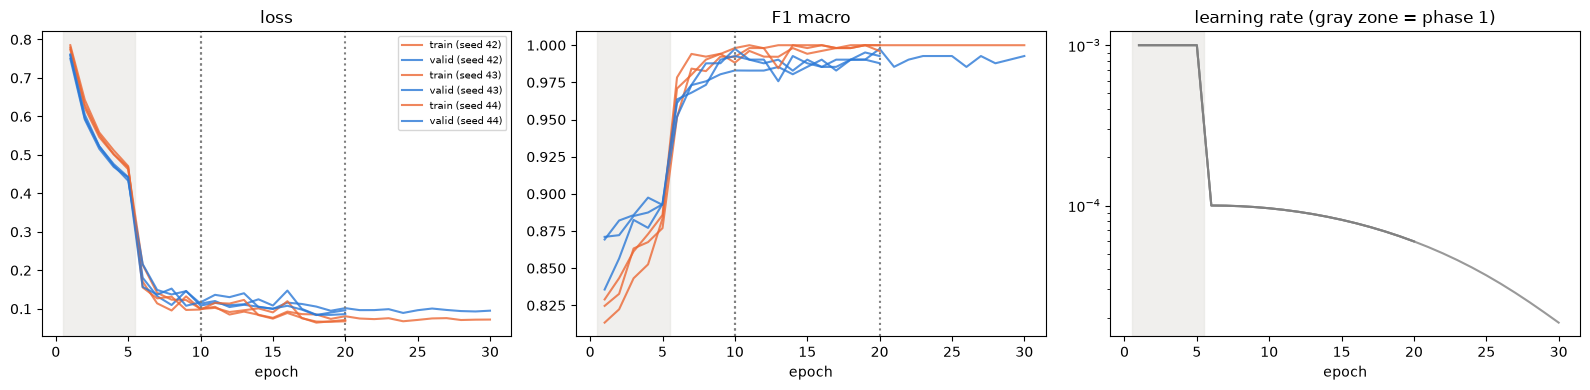

,best_epoch,epochs_run,minutes,device,n_params,trainable_phase2
42,20,30,1.04,cuda,14716227,12980739
43,10,20,0.68,cuda,14716227,12980739
44,10,20,0.68,cuda,14716227,12980739


In [7]:
histories = {seed: pd.read_csv(run_dir(seed) / 'history.csv') for seed in SEEDS}
dones = {seed: json.loads((run_dir(seed) / 'done.json').read_text()) for seed in SEEDS}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for seed, h in histories.items():
    axes[0].plot(h['epoch'], h['train_loss'], color='#eb6834', alpha=0.8, label=f'train (seed {seed})')
    axes[0].plot(h['epoch'], h['val_loss'], color='#2a78d6', alpha=0.8, label=f'valid (seed {seed})')
    axes[1].plot(h['epoch'], h['train_f1'], color='#eb6834', alpha=0.8, label=f'train (seed {seed})')
    axes[1].plot(h['epoch'], h['val_f1'], color='#2a78d6', alpha=0.8, label=f'valid (seed {seed})')
    axes[2].plot(h['epoch'], h['lr'], color='gray', alpha=0.8)
    for ax in axes[:2]:
        ax.axvline(dones[seed]['best_epoch'], color='gray', ls=':')
for ax in axes:
    ax.axvspan(0.5, CFG['head_epochs'] + 0.5, color='#e6e5e1', alpha=0.6, zorder=0)
axes[0].set(title='loss', xlabel='epoch')
axes[1].set(title='F1 macro', xlabel='epoch')
axes[2].set(title='learning rate (gray zone = phase 1)', xlabel='epoch', yscale='log')
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

pd.DataFrame(dones).T[['best_epoch', 'epochs_run', 'minutes', 'device', 'n_params', 'trainable_phase2']]

In [8]:
overfit_rows = []
for seed, h in histories.items():
    best = dones[seed]['best_epoch']
    at_best, last = h.iloc[best - 1], h.iloc[-1]
    end_phase1 = h[h['phase'] == 1].iloc[-1]
    overfit_rows.append({'seed': seed, 'val_f1_end_phase1': end_phase1['val_f1'], 'best_epoch': best,
                         'train_f1_at_best': at_best['train_f1'], 'val_f1_at_best': at_best['val_f1'],
                         'gap_at_best': at_best['train_f1'] - at_best['val_f1'],
                         'epoch_of_min_val_loss': int(h['val_loss'].idxmin()) + 1,
                         'val_loss_at_best': at_best['val_loss'], 'val_loss_last_epoch': last['val_loss']})
pd.DataFrame(overfit_rows).set_index('seed').round(4)

,val_f1_end_phase1,best_epoch,train_f1_at_best,val_f1_at_best,gap_at_best,epoch_of_min_val_loss,val_loss_at_best,val_loss_last_epoch
seed,,,,,,,,
42,0.8926,20,1.0000,0.9976,0.0024,24,0.1017,0.0951
43,0.8930,10,0.9882,0.9976,-0.0093,19,0.1084,0.0861
44,0.8932,10,0.9981,0.9927,0.0054,18,0.1169,0.0962


**Análisis de sobreajuste, subajuste y convergencia** (VGG16 y EfficientNet-B0, 3 semillas cada una):

- **Fase 1, red de ImageNet congelada:** entrenando solo la cabeza nueva, el F1 en `valid` llega a 0,89 en VGG16 y a 0,95–0,96 en EfficientNet-B0. Los rasgos de ImageNet ya separan bastante las especies. Al descongelar los últimos bloques (fase 2), VGG16 salta a 0,95 en la primera época, y las dos pasan de 0,98 hacia la época 8–9.
- **Convergencia:** las mejores épocas son la 20, la 10 y la 10 en VGG16, y la 18, la 24 y la 18 en EfficientNet-B0. La parada temprana (paciencia 10) cortó entre las épocas 20 y 34. Las dos llegan mucho antes que la CNN desde cero, cuyas mejores épocas son la 58, la 75 y la 84.
- **Sobreajuste:** en la mejor época, la brecha de F1 entre `train` y `valid` es de máximo 0,01 en las dos redes. La pérdida de `valid` no sube al final: en la última época vale 0,086–0,096 en VGG16 y 0,087–0,091 en EfficientNet-B0, igual o menos que en la mejor época. No hay sobreajuste visible. El F1 de `train` llega a ~1,0, así que la red ya ajusta todo `train` y más épocas no ayudarían.

## 7. Métricas en `valid` y comparación con la CNN base

F1 macro (promedio de las tres clases, todas pesan igual), exactitud y errores, por semilla, con la media y la desviación. Después la **comparación con la CNN base** (`dl/outputs/cnn_final/`): las dos se miden en los mismos 413 recortes de `valid`, así que también se puede ver, recorte por recorte, en qué se equivoca cada una. Más abajo, el reporte por clase y un intervalo de 95 % por *bootstrap*.

In [9]:
def predict_probs(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for x, y in loader:
            probs.append(F.softmax(model(x.to(DEVICE)), 1).cpu())
            ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


def load_model(seed):
    model = build_model(CFG, pretrained=False).to(DEVICE)   # the weights come from best.pt
    model.load_state_dict(torch.load(run_dir(seed) / 'best.pt', map_location=DEVICE))
    return model.eval()


models = {seed: load_model(seed) for seed in SEEDS}
valid_probs, rows = {}, []
for seed, model in models.items():
    probs, valid_true = predict_probs(model, valid_loader)
    valid_probs[seed] = probs
    pred = probs.argmax(1)
    rows.append({'seed': seed, 'accuracy': accuracy_score(valid_true, pred),
                 'f1_macro': f1_score(valid_true, pred, average='macro'), 'errors': int((pred != valid_true).sum())})
valid_table = pd.DataFrame(rows).set_index('seed').astype(float)
if len(SEEDS) > 1:
    per_seed = valid_table.copy()
    valid_table.loc['mean'] = per_seed.mean()
    valid_table.loc['std'] = per_seed.std()
valid_table.round(4)

,accuracy,f1_macro,errors
seed,,,
42,0.9976,0.9976,1.0000
43,0.9976,0.9976,1.0000
44,0.9927,0.9927,3.0000
mean,0.9960,0.9959,1.6667
std,0.0028,0.0028,1.1547


In [10]:
# The from-scratch CNN of cnn_final.ipynb (same classes as there), loaded only to compare.
class Block(nn.Module):
    def __init__(self, cin, cout, residual):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.conv2 = nn.Sequential(nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout)) if residual else None
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        out = self.conv2(self.conv1(x))
        if self.skip is not None:
            out = out + self.skip(x)
        return self.pool(F.relu(out))


class CNN(nn.Module):
    def __init__(self, blocks, width, residual, dropout, n_classes=3):
        super().__init__()
        chans = [3] + [width * 2 ** i for i in range(blocks)]
        self.features = nn.Sequential(*[Block(chans[i], chans[i + 1], residual) for i in range(blocks)])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(chans[-1], n_classes))

    def forward(self, x):
        return self.head(self.features(x))


cnn_seeds = [s for s in SEEDS if (CNN_DIR / f'seed{s}' / 'best.pt').is_file()]
HAVE_CNN = len(cnn_seeds) > 0
cnn_models, cnn_dones = {}, {}
for s in cnn_seeds:
    cfg = json.loads((CNN_DIR / f'seed{s}' / 'config.json').read_text())
    m = CNN(cfg['blocks'], cfg['width'], cfg['residual'], cfg['dropout']).to(DEVICE)
    m.load_state_dict(torch.load(CNN_DIR / f'seed{s}' / 'best.pt', map_location=DEVICE))
    cnn_models[s] = m.eval()
    cnn_dones[s] = json.loads((CNN_DIR / f'seed{s}' / 'done.json').read_text())

if HAVE_CNN:
    cnn_valid_probs = {s: predict_probs(m, valid_loader)[0] for s, m in cnn_models.items()}
    cnn_f1 = [f1_score(valid_true, p.argmax(1), average='macro') for p in cnn_valid_probs.values()]
    tl_f1 = valid_table.loc[SEEDS, 'f1_macro']
    comparison = pd.DataFrame({
        'CNN base (from scratch)': {'seeds': len(cnn_f1), 'val_f1_mean': np.mean(cnn_f1), 'val_f1_std': np.std(cnn_f1, ddof=1) if len(cnn_f1) > 1 else np.nan,
                                    'parameters': cnn_dones[cnn_seeds[0]]['n_params'],
                                    'best_epoch_mean': np.mean([d['best_epoch'] for d in cnn_dones.values()]),
                                    'train_minutes_mean': np.mean([d['minutes'] for d in cnn_dones.values()])},
        f'{ARCH} (transfer learning)': {'seeds': len(tl_f1), 'val_f1_mean': tl_f1.mean(), 'val_f1_std': tl_f1.std() if len(tl_f1) > 1 else np.nan,
                                         'parameters': dones[SEEDS[0]]['n_params'],
                                         'best_epoch_mean': np.mean([d['best_epoch'] for d in dones.values()]),
                                         'train_minutes_mean': np.mean([d['minutes'] for d in dones.values()])},
    }).T
    display(comparison.round(4))

    # Crop by crop, seed 42 of each: where do they disagree?
    s0 = SEEDS[0] if SEEDS[0] in cnn_valid_probs else cnn_seeds[0]
    tl_ok = valid_probs[SEEDS[0]].argmax(1) == valid_true
    cnn_ok = cnn_valid_probs[s0].argmax(1) == valid_true
    print(f'valid crops, {ARCH} seed {SEEDS[0]} vs CNN base seed {s0}:')
    display(pd.DataFrame([[int((tl_ok & cnn_ok).sum()), int((tl_ok & ~cnn_ok).sum())],
                          [int((~tl_ok & cnn_ok).sum()), int((~tl_ok & ~cnn_ok).sum())]],
                         index=[f'{ARCH} right', f'{ARCH} wrong'], columns=['CNN base right', 'CNN base wrong']))
else:
    print(f'no CNN base runs in {CNN_DIR}: run cnn_final.ipynb to compare')

,seeds,val_f1_mean,val_f1_std,parameters,best_epoch_mean,train_minutes_mean
CNN base (from scratch),3.0,0.9919,0.0014,4715747.0,72.3333,2.9633
vgg16 (transfer learning),3.0,0.9959,0.0028,14716227.0,13.3333,0.8000


valid crops, vgg16 seed 42 vs CNN base seed 42:


,CNN base right,CNN base wrong
vgg16 right,410,2
vgg16 wrong,0,1


In [11]:
main_seed = SEEDS[0]
main_pred = valid_probs[main_seed].argmax(1)
print(f'per-class report and interval below use seed {main_seed}')
report = pd.DataFrame(classification_report(valid_true, main_pred, labels=range(3), target_names=CLASSES,
                                            output_dict=True, zero_division=0)).T
display(report.round(4))

rng = np.random.default_rng(42)
boots = []
for _ in range(1000):
    idx = rng.integers(0, len(valid_true), len(valid_true))
    boots.append((f1_score(valid_true[idx], main_pred[idx], average='macro'), accuracy_score(valid_true[idx], main_pred[idx])))
ci = pd.DataFrame(np.percentile(np.array(boots), [2.5, 97.5], axis=0), index=['low', 'high'], columns=['f1_macro', 'accuracy'])
print('95% bootstrap interval on valid:')
ci.round(4)

per-class report and interval below use seed 42


,precision,recall,f1-score,support
ascaris,0.9927,1.0000,0.9963,136.0000
hookworm,1.0000,1.0000,1.0000,140.0000
trichuris,1.0000,0.9927,0.9963,137.0000
accuracy,0.9976,0.9976,0.9976,0.9976
macro avg,0.9976,0.9976,0.9976,413.0000
weighted avg,0.9976,0.9976,0.9976,413.0000


95% bootstrap interval on valid:


,f1_macro,accuracy
low,0.9924,0.9927
high,1.0000,1.0000


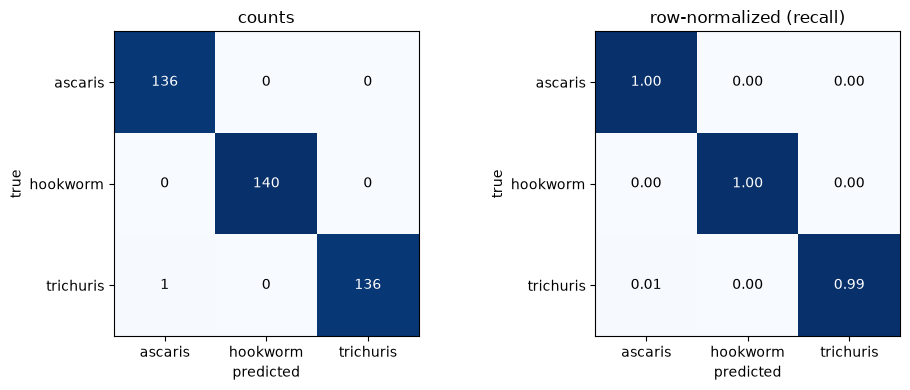

In [12]:
cm = confusion_matrix(valid_true, main_pred, labels=range(3))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, data, fmt) in zip(axes, [('counts', cm, '{:d}'), ('row-normalized (recall)', cm_norm, '{:.2f}')]):
    ax.imshow(data, cmap='Blues')
    ax.set(title=title, xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel='predicted', ylabel='true')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, fmt.format(data[i, j]), ha='center', va='center',
                    color='white' if data[i, j] > data.max() * 0.6 else 'black')
plt.tight_layout()
plt.show()

## 8. Confianza y rechazo

El sistema debe poder decir **consulte a un experto** cuando duda (PLAN §6.5). La confianza es la probabilidad máxima del softmax. La tabla muestra qué pasa si solo se aceptan las predicciones con confianza mayor que un umbral: la **cobertura** es la fracción de huevos que se aceptan y la **exactitud** es la de esos huevos aceptados. La confianza **no es una probabilidad calibrada**.

In [13]:
confidence = valid_probs[main_seed].max(1)
correct = main_pred == valid_true
print(f'mean confidence, correct: {confidence[correct].mean():.3f}')
if (~correct).any():
    print(f'mean confidence, wrong:   {confidence[~correct].mean():.3f}')

reject_rows = []
for threshold in [0.0, 0.5, 0.7, 0.9, 0.95, 0.99]:
    keep = confidence >= threshold
    reject_rows.append({'threshold': threshold, 'coverage': keep.mean(),
                        'accuracy_on_accepted': correct[keep].mean() if keep.any() else np.nan})
pd.DataFrame(reject_rows).set_index('threshold').round(4)

mean confidence, correct: 0.910
mean confidence, wrong:   0.356


,coverage,accuracy_on_accepted
threshold,,
0.00,1.0000,0.9976
0.50,0.9855,1.0000
0.70,0.9637,1.0000
0.90,0.7893,1.0000
0.95,0.2131,1.0000
0.99,0.0000,NaN


## 9. Errores e interpretabilidad (Grad-CAM)

Primero los recortes que la red clasifica mal en `valid`, con la especie real, la predicha y la confianza. Después **Grad-CAM**: un mapa de calor de las zonas que más pesaron en la decisión (rojo = más importante). Se calcula sobre la última activación convolucional (VGG16: 14 × 14, antes del último `MaxPool`; EfficientNet-B0: 7 × 7) y se estira a 224 × 224.

Para cada ejemplo se muestra la imagen, el Grad-CAM de esta red y el de la **CNN base** (su última convolución, de 7 × 7). Sirve para ver si las dos miran el huevo o el fondo. Se muestra el acierto más seguro de cada especie y los primeros errores. El PLAN pide que un parasitólogo de la UPB revise una muestra.

,crop_path,label,predicted,confidence
304,data/crops/valid/trichuris/Trichuris-trichiura...,trichuris,ascaris,0.356


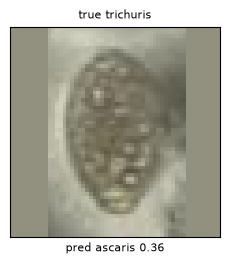

In [14]:
wrong_idx = np.where(~correct)[0]
errors = valid_frame.iloc[wrong_idx][['crop_path', 'label']].copy()
errors['predicted'] = [CLASSES[p] for p in main_pred[wrong_idx]]
errors['confidence'] = confidence[wrong_idx].round(3)
display(errors)

show = wrong_idx[:12]
fig, axes = plt.subplots(1, max(len(show), 1), figsize=(2.4 * max(len(show), 1), 3), squeeze=False)
for ax in axes[0]:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, i in zip(axes[0], show):
    ax.imshow(valid_imgs[i])
    ax.set_title(f'true {CLASSES[valid_true[i]]}', fontsize=8)
    ax.set_xlabel(f'pred {CLASSES[main_pred[i]]} {confidence[i]:.2f}', fontsize=8)
plt.tight_layout()
plt.show()

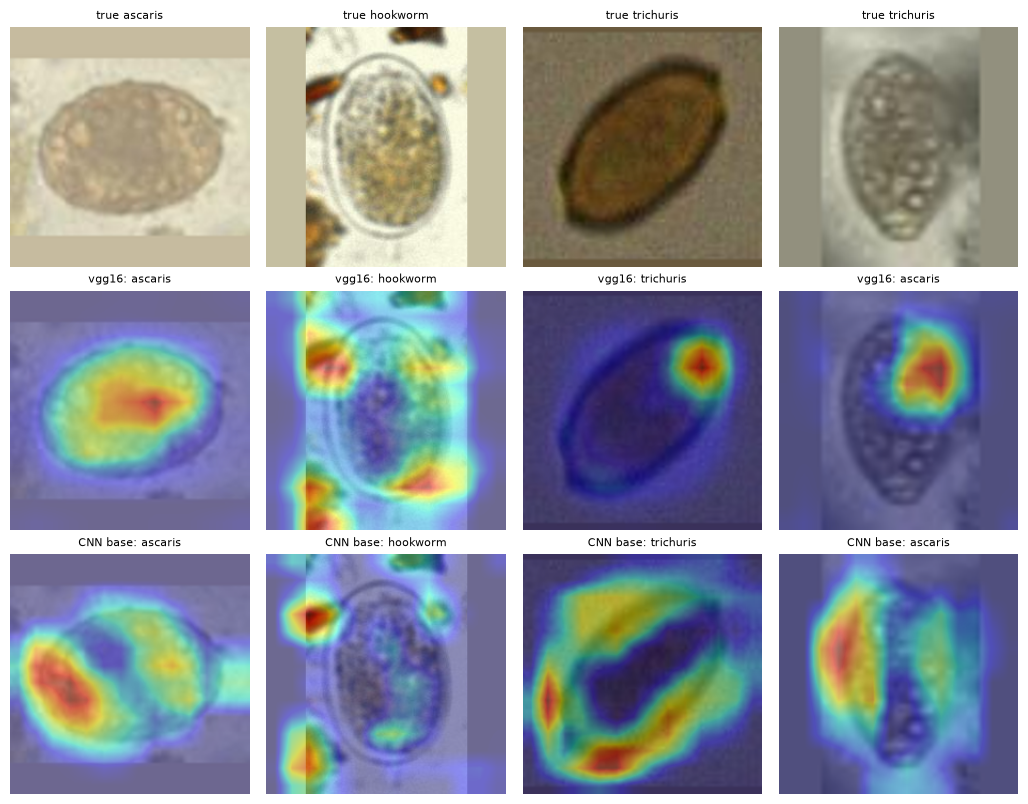

In [15]:
def grad_cam(model, layer, x):
    # Heat map (input size, 0..1) of the class the model predicts for the single image x (1, 3, H, W).
    store = {}

    def keep(module, inputs, output):
        store['a'] = output
        output.register_hook(lambda grad: store.update(g=grad))

    handle = layer.register_forward_hook(keep)
    model.eval()
    try:
        out = model(x)
        target = int(out.argmax(1).item())
        model.zero_grad()
        out[0, target].backward()
    finally:
        handle.remove()
    weights = store['g'].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * store['a']).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), target


def denormalize(x):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (x.detach().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


eval_tf = make_transform(None)
examples = []
for c in range(3):
    ok = np.where(correct & (valid_true == c))[0]
    if len(ok):
        examples.append(int(ok[np.argmax(confidence[ok])]))
examples += [int(i) for i in wrong_idx[:3]]

rows_shown = [(f'{ARCH}', models[main_seed], CAM_LAYER(models[main_seed]))]
if HAVE_CNN:
    cnn_main = cnn_models[cnn_seeds[0]]
    rows_shown.append(('CNN base', cnn_main, cnn_main.features[-1].conv2))
fig, axes = plt.subplots(1 + len(rows_shown), len(examples), figsize=(2.6 * len(examples), 2.7 * (1 + len(rows_shown))), squeeze=False)
for col, i in enumerate(examples):
    x = eval_tf(valid_imgs[i]).unsqueeze(0).to(DEVICE)
    img = denormalize(x[0])
    axes[0, col].imshow(img)
    axes[0, col].set_title(f'true {CLASSES[valid_true[i]]}', fontsize=8)
    for row, (name, model, layer) in enumerate(rows_shown, start=1):
        cam, target = grad_cam(model, layer, x)
        axes[row, col].imshow(img)
        axes[row, col].imshow(cam, cmap='jet', alpha=0.45)
        axes[row, col].set_title(f'{name}: {CLASSES[target]}', fontsize=8)
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

## 10. Recursos

Qué tan pesada y rápida es cada red. La latencia se mide en **CPU**, un recorte a la vez (como lo haría la app en la laptop de campo, PLAN RNF2), en la máquina donde corre el notebook: sirve de referencia, no como cifra final.

In [16]:
def cpu_latency_ms(model, runs=30):
    model = model.to('cpu').eval()
    sample = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    with torch.no_grad():
        for _ in range(5):
            model(sample)
        start = time.perf_counter()
        for _ in range(runs):
            model(sample)
    return (time.perf_counter() - start) / runs * 1000


cpu_tl = build_model(CFG, pretrained=False)
cpu_tl.load_state_dict(torch.load(run_dir(main_seed) / 'best.pt', map_location='cpu'))
resources = {ARCH: {'parameters': count(cpu_tl.parameters()), 'size_MB_float32': round(count(cpu_tl.parameters()) * 4 / 1e6, 1),
                    'cpu_latency_ms_per_crop': round(cpu_latency_ms(cpu_tl), 1),
                    'training_minutes': dones[main_seed]['minutes'], 'training_device': dones[main_seed]['device']}}
if HAVE_CNN:
    cfg = json.loads((CNN_DIR / f'seed{cnn_seeds[0]}' / 'config.json').read_text())
    cpu_cnn = CNN(cfg['blocks'], cfg['width'], cfg['residual'], cfg['dropout'])
    cpu_cnn.load_state_dict(torch.load(CNN_DIR / f'seed{cnn_seeds[0]}' / 'best.pt', map_location='cpu'))
    resources['CNN base'] = {'parameters': count(cpu_cnn.parameters()), 'size_MB_float32': round(count(cpu_cnn.parameters()) * 4 / 1e6, 1),
                             'cpu_latency_ms_per_crop': round(cpu_latency_ms(cpu_cnn), 1),
                             'training_minutes': cnn_dones[cnn_seeds[0]]['minutes'], 'training_device': cnn_dones[cnn_seeds[0]]['device']}
print('cpu threads:', torch.get_num_threads())
pd.DataFrame(resources).T

cpu threads: 16


,parameters,size_MB_float32,cpu_latency_ms_per_crop,training_minutes,training_device
vgg16,14716227,58.9,24.0,1.04,cuda
CNN base,4715747,18.9,7.4,2.58,cuda


## 11. Robustez a brillo y nitidez

El objetivo específico 3 pide evaluar la robustez con perturbaciones de brillo y de nitidez. Se aplican a los recortes de `valid` (las redes **no** se vuelven a entrenar) y se mide el F1 macro, para esta red y para la CNN base (semilla 42 de cada una). Brillo 1,0 y desenfoque 0 son las imágenes originales. Los aumentos de entrenamiento cubren brillo entre ×0,7 y ×1,3 (color 0,3) y desenfoque leve: más allá se mide extrapolación.

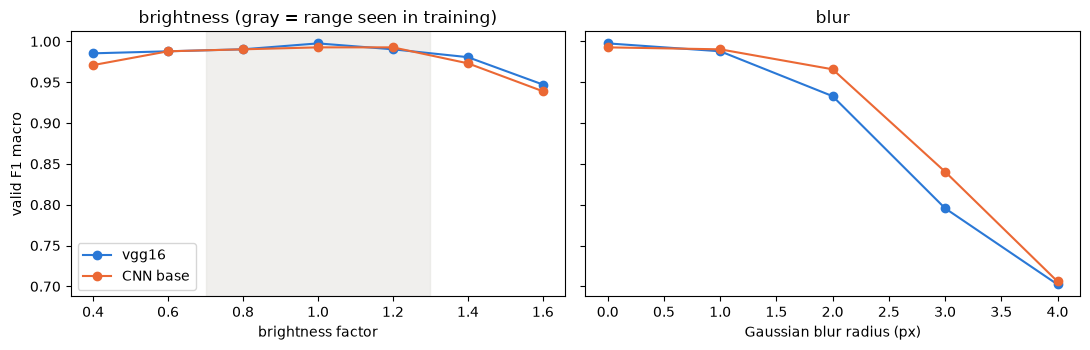

brightness,0.4,0.6,0.8,1.0,1.2,1.4,1.6
vgg16,0.9854,0.9879,0.9903,0.9976,0.9903,0.9807,0.9472
CNN base,0.9710,0.9879,0.9903,0.9927,0.9927,0.9731,0.9389


blur radius,0,1,2,3,4
vgg16,0.9976,0.9879,0.9329,0.7956,0.7023
CNN base,0.9927,0.9903,0.9658,0.8404,0.7060


In [17]:
BRIGHTNESS = [0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6]
BLUR_RADIUS = [0, 1, 2, 3, 4]   # Gaussian blur, px of the padded crop (before resizing to 224)


def f1_perturbed(model, perturb):
    images = [perturb(img) for img in valid_imgs]
    # num_workers=0: 24 short loaders with 8 workers each flood the log with temp-dir cleanup errors on /scratch
    loader = DataLoader(Crops(images, valid_y, None), batch_size=BATCH, shuffle=False, num_workers=0)
    probs, _ = predict_probs(model, loader)
    return f1_score(valid_y, probs.argmax(1), average='macro')


compared = {ARCH: models[main_seed]}
if HAVE_CNN:
    compared['CNN base'] = cnn_models[cnn_seeds[0]]
robust = {}
for name, model in compared.items():
    robust[(name, 'brightness')] = [f1_perturbed(model, lambda im, f=f: ImageEnhance.Brightness(im).enhance(f)) for f in BRIGHTNESS]
    robust[(name, 'blur')] = [f1_perturbed(model, lambda im, r=r: im.filter(ImageFilter.GaussianBlur(r)) if r else im) for r in BLUR_RADIUS]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for name, color in zip(compared, ['#2a78d6', '#eb6834']):
    axes[0].plot(BRIGHTNESS, robust[(name, 'brightness')], marker='o', color=color, label=name)
    axes[1].plot(BLUR_RADIUS, robust[(name, 'blur')], marker='o', color=color, label=name)
axes[0].axvspan(0.7, 1.3, color='#e6e5e1', alpha=0.6, zorder=0)
axes[0].set(title='brightness (gray = range seen in training)', xlabel='brightness factor', ylabel='valid F1 macro')
axes[1].set(title='blur', xlabel='Gaussian blur radius (px)')
axes[0].legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({name: values for (name, kind), values in robust.items() if kind == 'brightness'}, index=BRIGHTNESS).rename_axis('brightness').T.round(4))
pd.DataFrame({name: values for (name, kind), values in robust.items() if kind == 'blur'}, index=BLUR_RADIUS).rename_axis('blur radius').T.round(4)

## 12. Fotos externas: YOLO + red

La prueba que más importa: fotos que **no** vienen de Chula (celular por el ocular). El flujo es el del sistema completo, igual que en `cnn_final.ipynb`:

1. El **detector YOLO de 1 clase** (`DETECTOR_WEIGHTS`) encuentra los huevos en la foto.
2. Cada caja se **recorta** con 15 % de margen y se rellena a cuadrado.
3. La red clasifica cada recorte. **Con varias semillas, las probabilidades se promedian** (un conjunto de las 3 redes), igual que en `cnn_final.ipynb`. La CNN base clasifica los mismos recortes, para comparar.

Se usan las fotos con `uso = prueba` de `external.csv` (armado con `data_prep/src/build_external_csv.py`: las fotos sueltas originales más las carpetas `Ascaris/`, `Uncinaria/` y `Trichuris/`); las de `uso = desarrollo` se muestran pero no cuentan. `Strongyloides/` queda fuera a propósito (no es una de las 3 clases). Las fotos se usan **recortadas al círculo del ocular** (`data/external_fov/`, hechas con `data_prep/src/crop_field_of_view.py`). Solo se usan fotos **con huevos**: las de `Control/` (campos sin huevos) y `a-image3.png` quedaron fuera de la evaluación por decisión del equipo (PLAN §14, 2026-11-11).

**Límites que hay que decir en el informe:**
- No hay cajas reales dibujadas: el conteo compara **cantidades** (`found = min(cajas, huevos reales)`), no ubicaciones.
- Cada foto tiene una sola especie (la de su carpeta). `species_ok` es una cota aproximada: una falsa alarma que adivine la especie contaría como acierto.


In [18]:
external_photos = pd.read_csv(EXTERNAL_CSV)
photos_on_disk = {p.name for p in EXTERNAL_DIR.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES}
assert photos_on_disk == set(external_photos.image), 'fix external.csv first'
external_photos['n_items'] = external_photos.n_items.astype(int)
test_photos = external_photos[external_photos.uso == 'prueba']
print(f'{len(test_photos)} test photos with {test_photos.n_items.sum()} eggs')

assert DETECTOR_WEIGHTS.is_file(), f'missing detector weights: {DETECTOR_WEIGHTS}'
detector = YOLO(str(DETECTOR_WEIGHTS))
DET_DEVICE = 0 if DEVICE == 'cuda' else 'cpu'


def expand(box, margin, width, height):
    x1, y1, x2, y2 = box
    dw, dh = (x2 - x1) * margin, (y2 - y1) * margin
    return (max(0, int(round(x1 - dw))), max(0, int(round(y1 - dh))),
            min(width, int(round(x2 + dw))), min(height, int(round(y2 + dh))))


def classify(crops, model_dict):
    x = torch.stack([eval_tf(pad_to_square(c)) for c in crops]).to(DEVICE)
    with torch.no_grad():
        return torch.stack([F.softmax(m.to(DEVICE).eval()(x), 1).cpu() for m in model_dict.values()]).mean(0).numpy()


rows = []
for photo in external_photos.itertuples():
    path = EXTERNAL_DIR / photo.image
    img = ImageOps.exif_transpose(Image.open(path)).convert('RGB')  # upright: iPhone JPGs carry EXIF rotation, and YOLO boxes are in the rotated frame
    width, height = img.size
    result = detector.predict(source=img, imgsz=640, conf=CONF_LOWEST, max_det=MAX_BOXES_PER_PHOTO,
                              device=DET_DEVICE, verbose=False)[0]
    crops, meta = [], []
    for box, score in zip(result.boxes.xyxy.tolist(), result.boxes.conf.tolist()):
        x1, y1, x2, y2 = expand(box, MARGIN, width, height)
        if min(x2 - x1, y2 - y1) < 16:
            continue
        crops.append(img.crop((x1, y1, x2, y2)))
        meta.append((box, score))
    if not crops:
        continue
    tl_p = classify(crops, models)
    cnn_p = classify(crops, cnn_models) if HAVE_CNN else np.full_like(tl_p, np.nan)
    for (box, score), p, q in zip(meta, tl_p, cnn_p):
        rows.append({'image': photo.image, 'det_score': score, 'x1': box[0], 'y1': box[1], 'x2': box[2], 'y2': box[3],
                     'pred': CLASSES[int(p.argmax())], 'prob': float(p.max()),
                     'cnn_pred': CLASSES[int(q.argmax())] if HAVE_CNN else None, 'cnn_prob': float(np.max(q))})
external_dets = pd.DataFrame(rows, columns=['image', 'det_score', 'x1', 'y1', 'x2', 'y2', 'pred', 'prob', 'cnn_pred', 'cnn_prob'])
external_dets.groupby('image').size().rename('boxes found (any score)')

98 test photos with 101 eggs


image
a-image.png     2
a-image2.png    3
a-n001.jpg      1
a-n002.jpg      1
a-n003.jpg      1
               ..
t-n026.jpg      1
t-n027.jpg      1
t-n028.jpg      3
t-n029.jpg      1
t-n030.jpg      2
Name: boxes found (any score), Length: 99, dtype: int64

In [19]:
real = test_photos.set_index('image').n_items
species_of = external_photos.set_index('image').species


def external_summary(conf):
    kept = external_dets[(external_dets.det_score >= conf) & external_dets.image.isin(real.index)]
    boxes = kept.groupby('image').size().reindex(real.index, fill_value=0)
    found = np.minimum(boxes, real)
    summary = pd.DataFrame({'real_eggs': real, 'boxes': boxes, 'found': found, 'missed': real - found,
                            'false_alarms': boxes - found})
    for column, name in [('pred', f'species_ok_{ARCH}'), ('cnn_pred', 'species_ok_cnn_base')]:
        right = kept[kept[column] == kept.image.map(species_of)].groupby('image').size().reindex(real.index, fill_value=0)
        summary[name] = np.minimum(right, found)
    return summary


per_photo = external_summary(CONF_THRESHOLD)

# Totals by species, this network vs the CNN base.
by_species = external_summary(CONF_THRESHOLD)
by_species['group'] = species_of.reindex(by_species.index)
by_species = by_species.groupby('group').sum()
by_species.loc['total'] = by_species.sum()
eggs_found = by_species['found'].replace(0, np.nan)
for column in [c for c in by_species.columns if c.startswith('species_ok')]:
    by_species[column.replace('species_ok', 'species_rate')] = (by_species[column] / eggs_found).round(3)
print(f'by species, detector threshold {CONF_THRESHOLD}')
display(by_species)
per_photo.insert(0, 'species', species_of.reindex(per_photo.index))
per_photo.loc['total'] = per_photo.drop(columns='species').sum()
print(f'detector threshold {CONF_THRESHOLD}')
display(per_photo)

shown = external_dets[external_dets.det_score >= CONF_THRESHOLD]
display(shown[['image', 'det_score', 'pred', 'prob', 'cnn_pred', 'cnn_prob']].round(3))

curve = pd.DataFrame({conf: external_summary(conf).sum() for conf in [0.05, 0.1, 0.25, 0.5, 0.75]}).T
curve.index.name = 'det_conf'
print('same totals at other detector thresholds')
curve

by species, detector threshold 0.25


,real_eggs,boxes,found,missed,false_alarms,species_ok_vgg16,species_ok_cnn_base,species_rate_vgg16,species_rate_cnn_base
group,,,,,,,,,
ascaris,33,34,33,0,1,33,30,1.000,0.909
hookworm,35,40,35,0,5,35,34,1.000,0.971
trichuris,33,34,32,1,2,31,30,0.969,0.938
total,101,108,100,1,8,99,94,0.990,0.940


detector threshold 0.25


,species,real_eggs,boxes,found,missed,false_alarms,species_ok_vgg16,species_ok_cnn_base
image,,,,,,,,
a-image.png,ascaris,2,2,2,0,0,2,1
h-image.png,hookworm,2,2,2,0,0,2,2
h-image2.png,hookworm,1,1,1,0,0,1,1
t-image.png,trichuris,2,1,1,1,0,1,1
t-image2.png,trichuris,1,1,1,0,0,1,1
...,...,...,...,...,...,...,...,...
h-n029.jpg,hookworm,1,2,1,0,1,1,1
h-n030.jpg,hookworm,1,2,1,0,1,1,1
h-n031.jpg,hookworm,1,1,1,0,0,1,1


,image,det_score,pred,prob,cnn_pred,cnn_prob
0,a-image.png,0.901,ascaris,0.825,ascaris,0.952
1,a-image.png,0.718,ascaris,0.540,trichuris,0.674
2,a-image2.png,0.886,ascaris,0.823,ascaris,0.957
5,h-image.png,0.767,hookworm,0.848,hookworm,0.837
6,h-image.png,0.692,hookworm,0.816,hookworm,0.752
...,...,...,...,...,...,...
172,h-n029.jpg,0.340,hookworm,0.928,hookworm,0.941
175,h-n030.jpg,0.865,hookworm,0.910,hookworm,0.943
176,h-n030.jpg,0.417,hookworm,0.933,hookworm,0.877
178,h-n031.jpg,0.882,hookworm,0.869,hookworm,0.925


same totals at other detector thresholds


,real_eggs,boxes,found,missed,false_alarms,species_ok_vgg16,species_ok_cnn_base
det_conf,,,,,,,
0.05,101,118,101,0,17,100,95
0.10,101,114,101,0,13,100,95
0.25,101,108,100,1,8,99,94
0.50,101,105,100,1,5,99,94
0.75,101,93,91,10,2,89,87


99 annotated photos saved in dl/outputs/transfer_vgg16/external_annotated


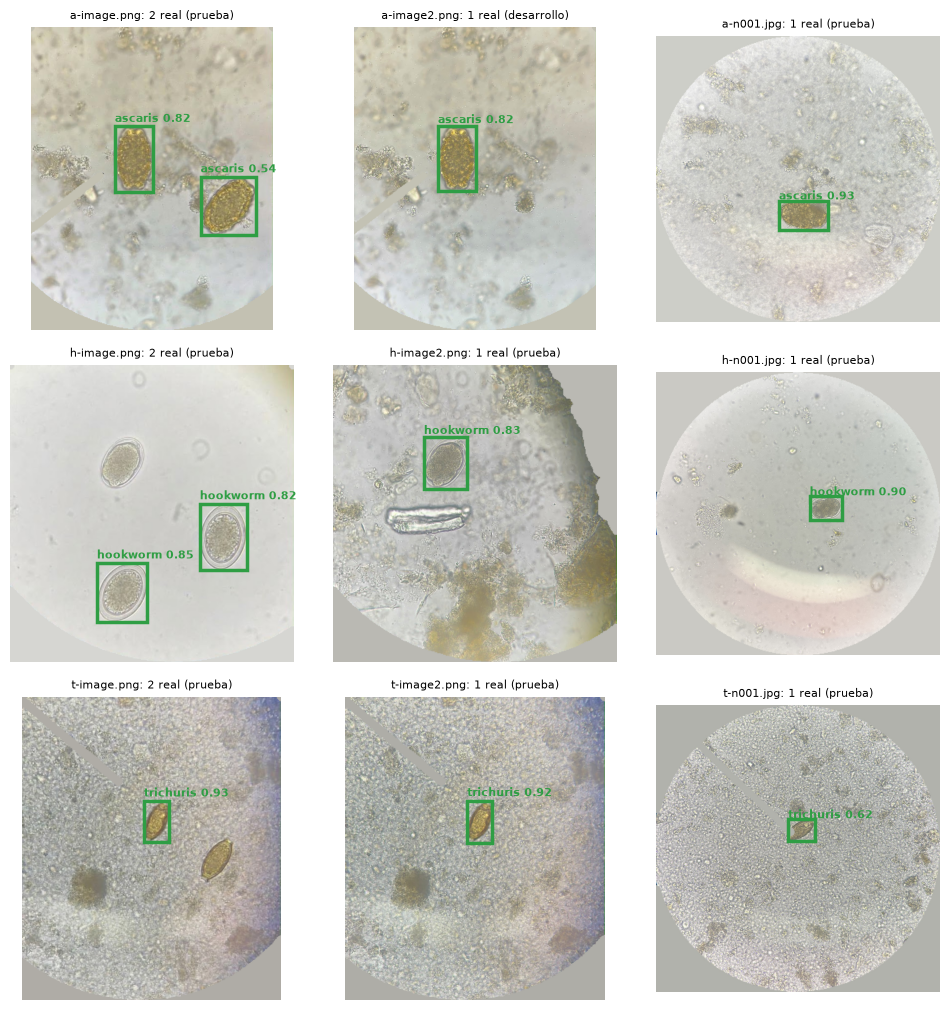

In [20]:
# Every photo is saved with its boxes (for the slides); only a sample per species is drawn here.
ANNOTATED_DIR = OUT_DIR / 'external_annotated'
ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)
PER_GROUP = 3


def draw(ax, photo):
    ax.imshow(ImageOps.exif_transpose(Image.open(EXTERNAL_DIR / photo.image)))
    for box in shown[shown.image == photo.image].itertuples():
        color = '#2f9e44' if box.pred == photo.species else '#d62828'
        ax.add_patch(Rectangle((box.x1, box.y1), box.x2 - box.x1, box.y2 - box.y1,
                               fill=False, edgecolor=color, linewidth=2.5))
        ax.text(box.x1, box.y1 - 10, f'{box.pred} {box.prob:.2f}', color=color, fontsize=8, fontweight='bold')
    ax.set_title(f'{photo.image}: {photo.n_items} real ({photo.uso})', fontsize=8)
    ax.axis('off')


for photo in external_photos.itertuples():
    fig, ax = plt.subplots(figsize=(5, 5))
    draw(ax, photo)
    fig.savefig(ANNOTATED_DIR / f'{Path(photo.image).stem}.jpg', dpi=110, bbox_inches='tight')
    plt.close(fig)
print(f'{len(external_photos)} annotated photos saved in {ANNOTATED_DIR.relative_to(ROOT)}')

groups = external_photos.assign(group=external_photos.species).groupby('group', sort=True)
sample = [photo for _, g in groups for photo in g.head(PER_GROUP).itertuples()]
fig, axes = plt.subplots(groups.ngroups, PER_GROUP, figsize=(3.2 * PER_GROUP, 3.4 * groups.ngroups), squeeze=False)
for ax in axes.ravel():
    ax.axis('off')
for (row, (_, g)) in enumerate(groups):
    for col, photo in enumerate(g.head(PER_GROUP).itertuples()):
        draw(axes[row, col], photo)
plt.tight_layout()
plt.show()


En las cajas, **verde** es que esta red acertó la especie de la foto y **rojo** que falló. El primer número es la especie predicha y el segundo, la confianza.

**Análisis de las externas** (98 fotos de prueba recortadas al ocular, 101 huevos, detector a 0,25):

- **Detector:** encuentra 100 de los 101 huevos, con 108 cajas. Las 8 cajas de más incluyen huevos reales que no se contaron, porque se asumió un huevo por foto.
- **Especie:** sobre los mismos recortes, VGG16 acierta 99 de 100, EfficientNet-B0 98 de 100 y la CNN base 94 de 100. Los 2 errores de EfficientNet-B0 son uncinarias leídas como *Ascaris*; el de VGG16, un *Trichuris*.
- **Confianza:** de los 2 errores de EfficientNet-B0, uno tiene 49 % de confianza (la app lo manda a revisión) y el otro 70 %, que pasaría sin revisión. El umbral de 65 % no atrapa todos los errores.
- **Caída frente a `valid`:** 0,6 puntos en VGG16, 1,4 en EfficientNet-B0 y 5 en la CNN, todas dentro del criterio del PLAN (máximo 10 puntos). Con la foto completa, sin recortar, el detector encuentra 93 huevos y las redes aciertan 90 (VGG16), 92 (EfficientNet-B0) y 85 (CNN) de 93.
- **Límites:** una sola fuente, especie según la carpeta, conteos asumidos, huevos repetidos en varias fotos y un recorte al ocular que se eligió después de ver resultados.

## 13. Prueba final en `test` (una sola vez)

`test` está congelado: no se usa para elegir modelos ni hiperparámetros. Esta celda solo corre si se pone `FINAL_TEST = True` en la sección 1, y debería hacerse **una sola vez**, con el modelo ya fijado y con el visto bueno del equipo.

In [21]:
if FINAL_TEST:
    test_imgs, test_y = load(df_all[df_all['split'] == 'test'])
    test_loader = make_loader(test_imgs, test_y, None, shuffle=False)
    test_rows = []
    for seed, model in models.items():
        probs, test_true = predict_probs(model, test_loader)
        pred = probs.argmax(1)
        test_rows.append({'seed': seed, 'accuracy': accuracy_score(test_true, pred),
                          'f1_macro': f1_score(test_true, pred, average='macro'), 'errors': int((pred != test_true).sum())})
    display(pd.DataFrame(test_rows).set_index('seed').round(4))
    test_pred = predict_probs(models[main_seed], test_loader)[0].argmax(1)
    display(pd.DataFrame(confusion_matrix(test_true, test_pred, labels=range(3)), index=CLASSES, columns=CLASSES))
else:
    print('FINAL_TEST = False: test stays frozen and is not loaded')

FINAL_TEST = False: test stays frozen and is not loaded


## Conclusiones: CNN base, VGG16 y EfficientNet-B0

Las tres redes usan los mismos recortes, el mismo split, los mismos aumentos (`mid`), la misma cabeza y las mismas semillas (42, 43 y 44). Los números salen de `transfer_learning.ipynb` (VGG16), `transfer_learning_efficientnet_b0.ipynb` (EfficientNet-B0) y `cnn_final.ipynb` (CNN base), corridos en una H100 el 11-nov-2026.

| Red | Parámetros | Pesos (float32) | F1 macro en `valid` (3 semillas) | Mejor época (media) | Entrenamiento (min, media) | Especie correcta en externas |
|---|---|---|---|---|---|---|
| CNN base (desde cero) | 4,72 M | 18,9 MB | 0,9919 ± 0,0014 | 72 | 3,0 | 94 / 100 (94 %) |
| VGG16 (ImageNet) | 14,72 M | 58,9 MB | 0,9959 ± 0,0028 | 13 | 0,8 | **99 / 100 (99 %)** |
| **EfficientNet-B0 (ImageNet)** | **4,01 M** | **16,0 MB** | 0,9935 ± 0,0014 | 20 | 1,0 | 98 / 100 (98 %) |

"Externas" son 98 fotos de celular con 101 huevos, **recortadas al círculo del ocular** (`data/external_fov/`, hechas con `data_prep/src/crop_field_of_view.py`). Con el detector a 0,25, YOLO encuentra 100 de los 101 huevos, y la columna cuenta en cuántos de esos acierta la especie cada red (con las 3 semillas promediadas). Con las fotos completas, sin recortar, YOLO encontraba 93 y los aciertos eran 85 (CNN), 90 (VGG16) y 92 (EfficientNet-B0).

**Hallazgos**

1. **En `valid` las tres redes son equivalentes.** Las diferencias de F1 (0,992 a 0,996) son del tamaño de la desviación entre semillas. Con estos datos, `valid` no sirve para separarlas.
2. **El preentrenamiento acelera el aprendizaje.** Con la red de ImageNet congelada (fase 1), el F1 en `valid` ya llega a 0,89 en VGG16 y a 0,95 en EfficientNet-B0. Las redes preentrenadas llegan a su mejor época en 13 a 20 épocas, frente a 72 de la CNN desde cero.
3. **No hay sobreajuste visible en ninguna.** En la mejor época, la diferencia de F1 entre `train` y `valid` es de máximo 0,01, y la pérdida de `valid` no sube al final.
4. **Robustez (sección 11).** Con cambios de brillo las tres se comportan parecido. En el extremo (brillo ×1,6), EfficientNet-B0 conserva un F1 de 0,954, contra 0,947 de VGG16 y 0,939 de la CNN. El desenfoque fuerte las degrada a todas: con radio 3, el F1 queda entre 0,80 y 0,84.
5. **En las fotos externas, el preentrenamiento sí marca la diferencia.** La CNN desde cero baja a 94 %, mientras que las dos redes preentrenadas casi no bajan: 99 % (VGG16) y 98 % (EfficientNet-B0). Entre ellas dos, la diferencia es de un solo huevo.
6. **Recortar la foto al círculo del ocular ayuda sobre todo al detector.** YOLO pasa de encontrar 93 a encontrar 100 de los 101 huevos, y las tres redes aciertan más especies.

**Por qué EfficientNet-B0 puede ser la mejor opción para el sistema**

Rinde igual que VGG16 en `valid`, dentro del ruido, con **3,7 veces menos parámetros** (4,0 M frente a 14,7 M) y unos pesos de 16 MB frente a 59 MB. Es incluso más pequeña que la CNN base. En CPU, un recorte a la vez, tarda casi lo mismo que la CNN (11,1 ms frente a 9,4 ms en la misma corrida), mientras que VGG16 tarda unas 3 veces más (24,0 ms frente a 7,4 ms). En las fotos externas queda prácticamente empatada con VGG16 (98 % frente a 99 %, un huevo de diferencia). Es justo el criterio del PLAN (§6.3) para la laptop de campo: la red más liviana que rinda casi igual a la mejor. Ese criterio se apoya en `valid` y en el tamaño, no en las fotos externas, que así siguen siendo una prueba independiente.

**Cumplimiento de los objetivos**

- **F1 macro ≥ 0,85 en la prueba interna:** se cumple en `valid` (0,99 en las tres) y en `test`, que se corrió una sola vez en `comparison.ipynb` (11-nov-2026) con EfficientNet-B0 ya elegida: 0,993 (CNN), 0,995 (VGG16) y 0,998 (EfficientNet-B0).
- **Caída de máximo 10 puntos con imágenes externas:** se cumple en las tres, con una diferencia de métrica. En las externas se mide el acierto de especie sobre los huevos detectados, no el F1. Contra el F1 de `valid`, la caída es de unos 5 puntos en la CNN, 0,6 en VGG16 y 1,4 en EfficientNet-B0.
- **Grad-CAM revisado por un parasitólogo:** pendiente.

**Limitaciones**

- **La prueba externa es preliminar:**
  - viene de una sola fuente (mismo microscopio y mismo celular);
  - la especie sale de la carpeta de cada foto y no la confirmó un experto;
  - el número de huevos por foto se asumió en 1 y no se contó (las "cajas de más" que se revisaron resultaron ser huevos reales);
  - el mismo huevo aparece en varias fotos, así que hay menos de 93 huevos independientes;
  - no hay cajas dibujadas a mano: el conteo compara cantidades, no ubicaciones.

  Aun suponiendo independencia, los intervalos de 95 % (Wilson) son amplios: CNN de 87,5 % a 97,2 %, VGG16 de 94,6 % a 99,8 % y EfficientNet-B0 de 93,0 % a 99,4 %. VGG16 y EfficientNet-B0 no se pueden separar con estos datos.
- **El recorte al círculo del ocular se decidió después de ver los resultados externos.** Por eso las cifras con recorte son algo optimistas. Además, la app de demostración todavía analiza la foto completa, sin recortar.
- **Con el recorte al círculo, el detector deja escapar 1 de los 101 huevos** según los conteos actuales (8 con la foto completa, 7 de ellos uncinarias). Los huevos que no detecta no llegan al clasificador.
- **Las fotos de Chula llegaron estiradas** a 640 × 640 (unos 7 % en horizontal). Además, el fondo de la foto completa delata la especie (lo mostró el análisis exploratorio). Al recortar el huevo, ese atajo casi desaparece: con el huevo tapado, las redes quedan al nivel del azar.
- **Solo hay 3 clases.** Cualquier objeto que el detector encierre se asigna a una de ellas: no existe la clase "otro".
- **Nota técnica:** las fotos de iPhone guardan su rotación en el EXIF. La evaluación externa lee ahora la foto ya girada (`ImageOps.exif_transpose`), igual que YOLO. Antes no lo hacía, y los recortes no coincidían con las cajas.

**Trabajo futuro**

- Anotar las fotos externas con cajas y conteos reales (Roboflow o labelme) y agrupar las fotos del mismo huevo.
- Pedir a un experto de la UPB que confirme la especie y revise los Grad-CAM.
- Agregar fotos de otras fuentes y campos sin huevos.
- Probar los aumentos pendientes del PLAN §5.8: viñeta del ocular, escala y JPEG.